In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Stratified split
from sklearn.model_selection import train_test_split

# Imputing data
from sklearn.impute import SimpleImputer

In [7]:
# Cleaned Dataset as obtained from the Data Acquisition File
df = pd.read_csv("cleaned_dataset.csv")
# df = df.drop[]
display(df.head())
print('\nShape of Dataset: ', df.shape)

,ISO,Country Name,EG.ELC.ACCS.ZS,FP.CPI.TOTL.ZG,IT.NET.USER.ZS,NE.TRD.GNFS.ZS,NV.AGR.TOTL.ZS,NV.IND.TOTL.ZS,NY.GDP.MKTP.KD.ZG,SL.UEM.TOTL.ZS,SP.DYN.IMRT.IN,Region,ServiceSector,DominantSector,HDI
0,AFG,Afghanistan,85.300000,-4.644709,15.928400,66.999578,34.743247,13.449823,2.266944,14.008000,49.900000,"Middle East, North Africa, Afghanistan & Pakistan",51.806930,Service,0.496
1,AFE,Africa Eastern and Southern,50.667516,7.399186,27.800000,56.283721,15.305933,26.467975,1.941382,7.676548,41.969085,Aggregates,58.226091,Service,NaN
2,AFW,Africa Western and Central,57.064737,5.221168,38.500000,NaN,24.321381,23.244644,3.644591,3.203355,57.353682,Aggregates,52.433975,Service,NaN
3,ALB,Albania,100.000000,4.758346,83.135592,82.352493,16.274239,23.160712,4.015417,10.669000,8.300000,Europe & Central Asia,60.565049,Service,0.810
4,DZA,Algeria,100.000000,9.322174,76.197601,43.739798,13.369245,37.547655,4.100000,11.645000,19.700000,"Middle East, North Africa, Afghanistan & Pakistan",49.083100,Service,0.763



Shape of Dataset:  (266, 15)


In [8]:
# Removing any and all rows that do not have a HDI value as we shouldn't perform imputation on the response variable.
df = df.loc[~df['HDI'].isna()]

In [9]:
# Finding out the data distribution in the remaining dataset:
print(df.shape)
display(df.head())
display(df.describe())
display(df.isna().sum())

(192, 15)


,ISO,Country Name,EG.ELC.ACCS.ZS,FP.CPI.TOTL.ZG,IT.NET.USER.ZS,NE.TRD.GNFS.ZS,NV.AGR.TOTL.ZS,NV.IND.TOTL.ZS,NY.GDP.MKTP.KD.ZG,SL.UEM.TOTL.ZS,SP.DYN.IMRT.IN,Region,ServiceSector,DominantSector,HDI
0,AFG,Afghanistan,85.3,-4.644709,15.928400,66.999578,34.743247,13.449823,2.266944,14.008,49.9,"Middle East, North Africa, Afghanistan & Pakistan",51.806930,Service,0.496
3,ALB,Albania,100.0,4.758346,83.135592,82.352493,16.274239,23.160712,4.015417,10.669,8.3,Europe & Central Asia,60.565049,Service,0.810
4,DZA,Algeria,100.0,9.322174,76.197601,43.739798,13.369245,37.547655,4.100000,11.645,19.7,"Middle East, North Africa, Afghanistan & Pakistan",49.083100,Service,0.763
6,AND,Andorra,100.0,NaN,94.214996,NaN,0.478492,12.428226,2.583555,NaN,2.5,Europe & Central Asia,87.093282,Service,0.913
7,AGO,Angola,51.1,13.644102,37.885899,53.607013,20.909337,35.701247,1.320166,14.051,33.0,Sub-Saharan Africa,43.389416,Service,0.616


,EG.ELC.ACCS.ZS,FP.CPI.TOTL.ZG,IT.NET.USER.ZS,NE.TRD.GNFS.ZS,NV.AGR.TOTL.ZS,NV.IND.TOTL.ZS,NY.GDP.MKTP.KD.ZG,SL.UEM.TOTL.ZS,SP.DYN.IMRT.IN,ServiceSector,HDI
count,192.000000,175.000000,178.000000,166.000000,183.000000,183.000000,187.000000,176.000000,190.000000,183.000000,192.000000
mean,86.987500,10.253156,71.380057,94.210082,10.164048,26.185331,2.977049,6.765494,19.413158,63.650621,0.740995
std,23.265676,20.815756,25.419605,61.513950,10.002369,11.981739,4.628270,5.595546,17.408907,14.344016,0.151979
min,5.400000,-4.644709,7.172300,2.473729,0.015094,2.086302,-29.433272,0.130000,1.300000,19.331194,0.388000
25%,84.875000,3.590991,58.822826,51.262101,2.436646,18.437939,1.187590,3.117500,5.050000,53.161760,0.621750
50%,100.000000,5.865719,81.458550,81.849588,6.661449,24.563966,3.140091,5.159500,13.200000,64.658763,0.762500
75%,100.000000,9.302624,90.981476,114.987702,16.616926,32.061771,4.960761,8.332500,30.075000,74.939407,0.862000
max,100.000000,221.341644,100.000000,402.566968,43.988089,78.899528,33.795011,34.610000,71.900000,96.947243,0.972000


ISO                   0
Country Name          0
EG.ELC.ACCS.ZS        0
FP.CPI.TOTL.ZG       17
IT.NET.USER.ZS       14
NE.TRD.GNFS.ZS       26
NV.AGR.TOTL.ZS        9
NV.IND.TOTL.ZS        9
NY.GDP.MKTP.KD.ZG     5
SL.UEM.TOTL.ZS       16
SP.DYN.IMRT.IN        2
Region                0
ServiceSector         9
DominantSector        0
HDI                   0
dtype: int64

In [10]:
print(df['DominantSector'].unique())
display(df.dtypes)

<StringArray>
['Service', 'Industry', 'Missing', 'Agriculture']
Length: 4, dtype: str


ISO                      str
Country Name             str
EG.ELC.ACCS.ZS       float64
FP.CPI.TOTL.ZG       float64
IT.NET.USER.ZS       float64
NE.TRD.GNFS.ZS       float64
NV.AGR.TOTL.ZS       float64
NV.IND.TOTL.ZS       float64
NY.GDP.MKTP.KD.ZG    float64
SL.UEM.TOTL.ZS       float64
SP.DYN.IMRT.IN       float64
Region                   str
ServiceSector        float64
DominantSector           str
HDI                  float64
dtype: object

From the above missing values analysis, we can see that there are no missing values in `Region` or `DominantSector`, apart from `HDI`, for which it is necessary to have absolutely no missing values as it is the response variable.

Further analysis shows that the DominantSector already has the `Missing` class added wherever applicable.

With the `df.dtypes`, we can see that almost all the features are numerical with `np.float64` datatypes.
`Region` and `DominantSector` are two categorical features and thus imputation for them must be done accordingly.

In [11]:
# Investigating the class counts for HDI and other categorical variables
# Adding a column 'HDIClass' to make it easier to count

class0 = df['HDI'] < 0.550
class1 = (df['HDI'] >= 0.5500) & (df['HDI'] < 0.800)
class2 = df['HDI'] >= 0.80

In [12]:
df.loc[class0, 'HDIClass'] = 0
df.loc[class1, 'HDIClass'] = 1
df.loc[class2, 'HDIClass'] = 2
df['HDIClass'] = df['HDIClass'].astype(int)

In [13]:
df.value_counts('HDIClass')

HDIClass
1    92
2    74
0    26
Name: count, dtype: int64

### Dealing With multiple ways of imputing missing data:
For numerical data fields, there are primarly two ways to deal with missing data:
- Mean Imputation:
  - Filling the missing data with the mean of that feature.
  - Usually used when data does not contain many outliers and is decently concentrated in some area.
- Median Imputation:
  - Filling the missing data with the median of that feature
  - Median Imputation deals with outliers better as the median isn't affected much by the presence of outliers.

Based on these concepts, the features are divided in the following manner, in terms of the method of imputing the missing data:
`EG.ELC.ACCS.ZS`, `FP.CPI.TOTL.ZG`, `NV.IND.TOTL.ZS`, `SL.UEM.TOTL.ZS` are imputed using the **Median Imputation**.

The rest of the features are imputed by the **Mean Imputation**

Note: The imputer is fit only to the training dataset and is used to transform the validation and testing datasets.

In [14]:
# Creating the X and Y datasets:
X = df.copy().drop(columns=['HDI', 'HDIClass']).set_index(['ISO', 'Country Name'])
y = df.copy().set_index(['ISO', 'Country Name'])[['HDI', 'HDIClass']]

In [15]:
X.shape, y.shape, df.shape

((192, 12), (192, 2), (192, 16))

In [16]:
# Defining Mean and Median imputing features:
# Median features from the design decision
med_features = ['EG.ELC.ACCS.ZS', 'FP.CPI.TOTL.ZG', 'NV.IND.TOTL.ZS', 'SL.UEM.TOTL.ZS']
# Hardcoded mean features
mean_features = [
    'IT.NET.USER.ZS',
    'NE.TRD.GNFS.ZS',
    'NV.AGR.TOTL.ZS',
    'NY.GDP.MKTP.KD.ZG',
    'SP.DYN.IMRT.IN',
    'ServiceSector'
]

categorical_features = ['Region', 'DominantSector']

# All numerical features (mean features + median features)
numerical_features = med_features + mean_features

In [17]:
# Adding a missingness indicator for each of the features:
for feature in numerical_features:
    X['Missing_'+feature] = pd.isna(X[feature]).astype('int')

In [18]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y['HDIClass'], random_state=42)

In [19]:
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp['HDIClass'], random_state=42)

In [20]:
# Confirming a stratified split

display(y_test.value_counts('HDIClass')*100/len(y_test))
display(y_val.value_counts('HDIClass')*100/len(y_val))
display(y_train.value_counts('HDIClass')*100/len(y_train))

HDIClass
1    48.717949
2    38.461538
0    12.820513
Name: count, dtype: float64

HDIClass
1    47.368421
2    39.473684
0    13.157895
Name: count, dtype: float64

HDIClass
1    47.826087
2    38.260870
0    13.913043
Name: count, dtype: float64

In [21]:
# Initializing the imputers:
med_imputer = SimpleImputer(strategy='median')
mean_imputer = SimpleImputer(strategy='mean')

# Creating a copy to use for imputed df's
X_train_imputed = X_train.copy()
X_val_imputed = X_val.copy()
X_test_imputed = X_test.copy()

# Fitting imputers on their respective features
# fit_transform only for Training dataset
X_train_imputed[med_features] = med_imputer.fit_transform(X_train[med_features])
X_train_imputed[mean_features] = mean_imputer.fit_transform(X_train[mean_features])

# transform for validation and test sets
X_val_imputed[med_features] = med_imputer.transform(X_val[med_features])
X_val_imputed[mean_features] = mean_imputer.transform(X_val[mean_features])

X_test_imputed[med_features] = med_imputer.transform(X_test[med_features])
X_test_imputed[mean_features] = mean_imputer.transform(X_test[mean_features])

### Handling imputation for the categorical features:

Categorical features can be imputed by the following methods:
- Modal Imputation:
  - Fills the missing value with the most frequently occuring value
- 'Missing' Category:
  - A `Missing` category is added to the particular feature in place of the missing values.


Following this imputation, **one-hot encoding** is performed for each unique value of the categorical variables.

In the `Dataset_Acquisition.ipynb`, the `Missing` category was added for the `DominantSector` feature.
Similarly, for the `Region` feature, we are going ahead with the `Missing` category, as compared to Modal Imputation

Note: Appropriate handling of unseen values is also accounted for.

In [22]:
# Handing Imputing of categorical values using SimpleImputer:
cat_imputer = SimpleImputer(strategy='constant', fill_value='Missing')

# Safely copy categorical columns from the original splits first
X_train_imputed[categorical_features] = X_train[categorical_features]
X_val_imputed[categorical_features] = X_val[categorical_features]
X_test_imputed[categorical_features] = X_test[categorical_features]

# fit_transform called only on training dataset and only transform on val/test sets
X_train_imputed[categorical_features] = cat_imputer.fit_transform(X_train_imputed[categorical_features])
X_val_imputed[categorical_features] = cat_imputer.transform(X_val_imputed[categorical_features])
X_test_imputed[categorical_features] = cat_imputer.transform(X_test_imputed[categorical_features])

In [23]:
X_train_imputed.columns

Index(['EG.ELC.ACCS.ZS', 'FP.CPI.TOTL.ZG', 'IT.NET.USER.ZS', 'NE.TRD.GNFS.ZS',
       'NV.AGR.TOTL.ZS', 'NV.IND.TOTL.ZS', 'NY.GDP.MKTP.KD.ZG',
       'SL.UEM.TOTL.ZS', 'SP.DYN.IMRT.IN', 'Region', 'ServiceSector',
       'DominantSector', 'Missing_EG.ELC.ACCS.ZS', 'Missing_FP.CPI.TOTL.ZG',
       'Missing_NV.IND.TOTL.ZS', 'Missing_SL.UEM.TOTL.ZS',
       'Missing_IT.NET.USER.ZS', 'Missing_NE.TRD.GNFS.ZS',
       'Missing_NV.AGR.TOTL.ZS', 'Missing_NY.GDP.MKTP.KD.ZG',
       'Missing_SP.DYN.IMRT.IN', 'Missing_ServiceSector'],
      dtype='str')

In [24]:
# One-hot encode each split
X_train_encoded = pd.get_dummies(X_train_imputed, columns=categorical_features, drop_first=False)
X_val_encoded = pd.get_dummies(X_val_imputed, columns=categorical_features, drop_first=False)
X_test_encoded = pd.get_dummies(X_test_imputed, columns=categorical_features, drop_first=False)

# Handling unseen categorical values
X_val_encoded = X_val_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# Using the encoded data from here onward
X_train_imputed = X_train_encoded
X_val_imputed = X_val_encoded
X_test_imputed = X_test_encoded

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [26]:
# Target class labels from your existing y splits
y_train_cls = y_train["HDIClass"]
y_val_cls = y_val["HDIClass"]
y_test_cls = y_test["HDIClass"]

# Columns already imputed and one-hot encoded in X_train_imputed
passthrough_cols = [c for c in X_train_imputed.columns if c not in numerical_features]

In [27]:
scaler_ct = ColumnTransformer(
    transformers=[
        ("num_scaler", StandardScaler(), numerical_features),
        ("passthrough", "passthrough", passthrough_cols),
    ]
)

In [28]:
pipe_no_pca = Pipeline([
    ("scaler", scaler_ct),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_no_pca = cross_validate(
    pipe_no_pca,
    X_train_imputed,
    y_train_cls,
    cv=cv,
    scoring=["accuracy", "f1_macro", "f1_weighted"],
    return_train_score=True,
)

print("5-Fold Stratified CV on X_train_imputed (No PCA):")
print(f"  Train Accuracy : {cv_no_pca['train_accuracy'].mean():.3f} +/- {cv_no_pca['train_accuracy'].std():.3f}")
print(f"  CV Accuracy    : {cv_no_pca['test_accuracy'].mean():.3f} +/- {cv_no_pca['test_accuracy'].std():.3f}")
print(f"  CV Macro-F1    : {cv_no_pca['test_f1_macro'].mean():.3f} +/- {cv_no_pca['test_f1_macro'].std():.3f}")
print(f"  CV Weighted-F1 : {cv_no_pca['test_f1_weighted'].mean():.3f} +/- {cv_no_pca['test_f1_weighted'].std():.3f}")

5-Fold Stratified CV on X_train_imputed (No PCA):
  Train Accuracy : 0.965 +/- 0.008
  CV Accuracy    : 0.930 +/- 0.059
  CV Macro-F1    : 0.928 +/- 0.066
  CV Weighted-F1 : 0.930 +/- 0.059


In [30]:
#Now applying PCA
X_train_scaled = scaler_ct.fit_transform(X_train_imputed)
scaled_feature_names = numerical_features + passthrough_cols

pca_full = PCA(random_state=42)
pca_full.fit(X_train_scaled)
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
components = np.arange(1, len(evr) + 1)

In [31]:
n_90 = int(np.argmax(cum_evr >= 0.90) + 1)
n_95 = int(np.argmax(cum_evr >= 0.95) + 1)
print(f"Total features in X_train_imputed: {len(scaled_feature_names)}")
print(f"Components for >=90% variance: {n_90} ({cum_evr[n_90 - 1]:.1%})")
print(f"Components for >=95% variance: {n_95} ({cum_evr[n_95 - 1]:.1%})")

Total features in X_train_imputed: 31
Components for >=90% variance: 8 (90.1%)
Components for >=95% variance: 12 (95.9%)


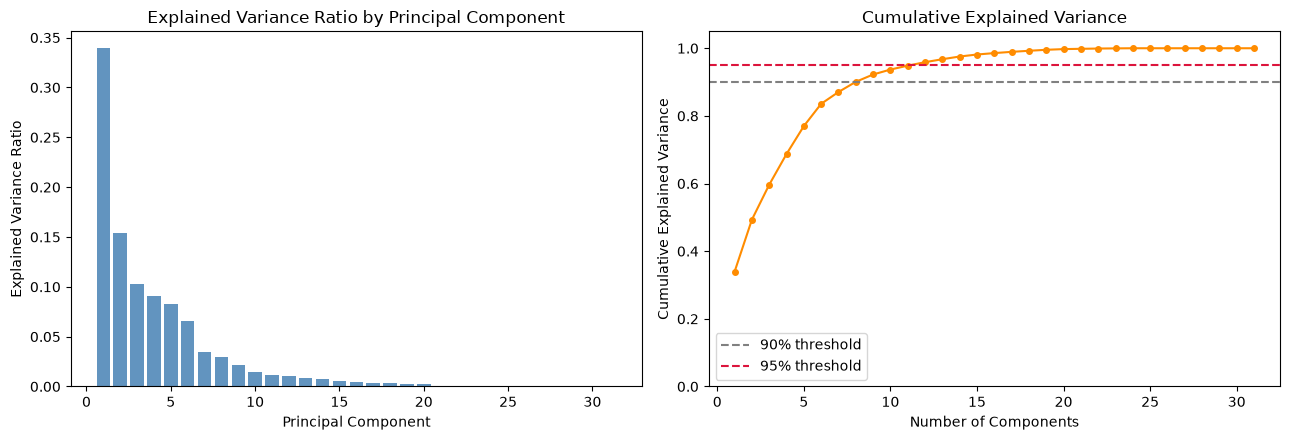

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(components, evr, color="steelblue", alpha=0.85)
axes[0].set_title("Explained Variance Ratio by Principal Component")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")

axes[1].plot(components, cum_evr, marker="o", markersize=4, color="darkorange")
axes[1].axhline(0.90, color="gray", linestyle="--", label="90% threshold")
axes[1].axhline(0.95, color="crimson", linestyle="--", label="95% threshold")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Explained Variance")
axes[1].set_ylim(0, 1.05)
axes[1].legend()

plt.tight_layout()

In [33]:
scaler_ct.fit(X_train_imputed)
scaled_cols = numerical_features + passthrough_cols

X_train_scaled_df = pd.DataFrame(
    scaler_ct.transform(X_train_imputed),
    index=X_train_imputed.index,
    columns=scaled_cols,
)
X_val_scaled_df = pd.DataFrame(
    scaler_ct.transform(X_val_imputed),
    index=X_val_imputed.index,
    columns=scaled_cols,
)
X_test_scaled_df = pd.DataFrame(
    scaler_ct.transform(X_test_imputed),
    index=X_test_imputed.index,
    columns=scaled_cols,
)

In [34]:
X_train_scaled_df.join(y_train).to_csv("train_scaled_features.csv")
X_val_scaled_df.join(y_val).to_csv("val_scaled_features.csv")
X_test_scaled_df.join(y_test).to_csv("test_scaled_features.csv")

In [35]:
pca = PCA(n_components=0.95, random_state=42)
pca.fit(X_train_scaled_df)
pc_cols = [f"PC{i + 1}" for i in range(pca.n_components_)]

X_train_pca_df = pd.DataFrame(
    pca.transform(X_train_scaled_df),
    index=X_train_imputed.index,
    columns=pc_cols,
)
X_val_pca_df = pd.DataFrame(
    pca.transform(X_val_scaled_df),
    index=X_val_imputed.index,
    columns=pc_cols,
)
X_test_pca_df = pd.DataFrame(
    pca.transform(X_test_scaled_df),
    index=X_test_imputed.index,
    columns=pc_cols,
)

In [36]:
X_train_pca_df.join(y_train).to_csv("train_pca_features.csv")
X_val_pca_df.join(y_val).to_csv("val_pca_features.csv")
X_test_pca_df.join(y_test).to_csv("test_pca_features.csv")